# 02 탐색: 회사 주변 식당은 어떻게 퍼져 있나

강의 OT의 2단계 **"현상 발견"** 입니다. 추천을 만들기 전에 데이터가 어떤 모양인지 먼저 봅니다.

| 항목 | 내용 |
|---|---|
| 입력 | `restaurants.csv` (노트북 01 결과, 식당 1곳 = 1행, **실제 데이터**) |
| 질문 | ① 어떤 메뉴가 많은가 ② 걸어서 몇 분 거리에 몰려 있나 ③ 예외나 구조적 패턴이 있나 |
| 주의 | 이 노트북은 **묘사**만 합니다. "왜 그런지(원인)"는 주장하지 않습니다. |

In [1]:
# Colab에서 한글 그래프 글꼴 준비
try:
    import koreanize_matplotlib
except ImportError:
    %pip install -q koreanize-matplotlib
    import koreanize_matplotlib
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# 데이터 불러오기: 내 폴더 → (Colab이면) 업로드 → 예시 데이터 순서로 찾음
import os
CANDIDATES = ["restaurants.csv", "../data/raw/restaurants.csv", "data/raw/restaurants.csv"]
path = next((p for p in CANDIDATES if os.path.exists(p)), None)
if path is None:
    try:
        from google.colab import files
        print("restaurants.csv 를 골라 주세요")
        path = list(files.upload().keys())[0]
    except ImportError:
        path = "../data/sample/restaurants_sample.csv"
df = pd.read_csv(path)
print(path, df.shape)

restaurants.csv (1343, 13)


## 0. 데이터 점검 (한 행의 의미와 빈칸)

In [3]:
print("한 행 = 식당 1곳. ID 중복:", df["restaurant_id"].duplicated().sum())
print("데이터 종류:", list(df["data_type"].unique()))
df.isna().sum()

한 행 = 식당 1곳. ID 중복: 0
데이터 종류: ['실제']


restaurant_id       0
name                0
menu_category       0
kakao_category      0
distance_m          0
walk_min            0
address             0
phone             387
x                   0
y                   0
place_url           0
data_type           0
collected_at        0
dtype: int64

- 전화번호만 빈칸이 있고, 분석에 쓰는 칸(메뉴·거리·좌표)은 모두 채워져 있습니다.
- **카카오 API에는 가격과 별점이 없습니다.** 그래서 가격대와 평점은 직원 리뷰(예시·가상 데이터)에서 만들어야 합니다.

## 1. 어떤 메뉴가 많은가

In [4]:
cnt = df["menu_category"].value_counts()
share = (cnt / cnt.sum() * 100).round(1)
pd.DataFrame({"식당 수": cnt, "비율(%)": share})

,식당 수,비율(%)
menu_category,,
한식,315,23.5
고기,158,11.8
술집,153,11.4
일식,150,11.2
양식,97,7.2
횟집·해산물,93,6.9
간식,87,6.5
중식,69,5.1
분식,51,3.8


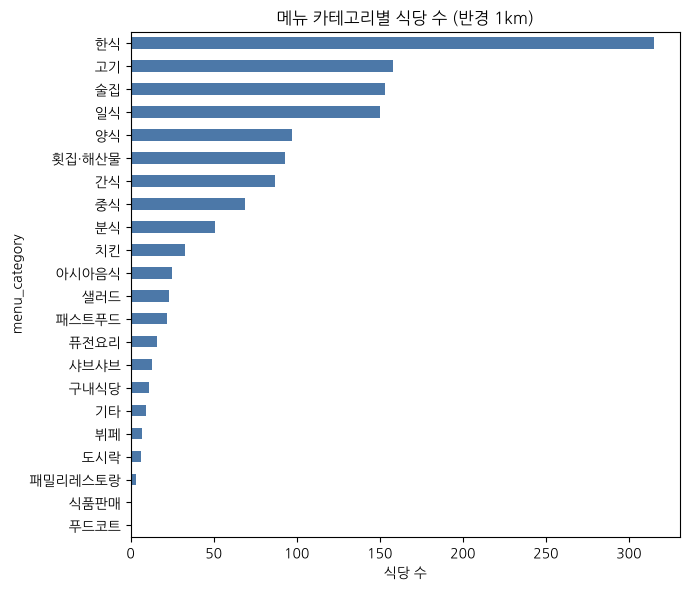

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
cnt.sort_values().plot.barh(ax=ax, color="#4C78A8")
ax.set_title("메뉴 카테고리별 식당 수 (반경 1km)")
ax.set_xlabel("식당 수")
plt.tight_layout(); plt.show()

**식사용이 아닌 항목 정리:** `간식`(빵집·디저트), `식품판매`, `구내식당`, `푸드코트`는 점심·저녁 추천 대상에서 뺄지 정해야 합니다. 아래에서 몇 곳인지 확인합니다.

In [6]:
NOT_MEAL = ["간식", "식품판매", "구내식당", "푸드코트"]
print("식사용 아님 후보:", df["menu_category"].isin(NOT_MEAL).sum(), "곳")
meal = df[~df["menu_category"].isin(NOT_MEAL)].copy()
print("추천 후보 식당:", len(meal), "곳")

식사용 아님 후보: 100 곳
추천 후보 식당: 1243 곳


## 2. 걸어서 몇 분 거리에 있나

In [7]:
meal["도보"] = pd.cut(meal["walk_min"], [-1, 5, 10, 15], labels=["5분 이내", "6~10분", "11~15분"])
meal["도보"].value_counts().sort_index()

도보
5분 이내     443
6~10분     479
11~15분    321
Name: count, dtype: int64

In [8]:
top = meal["menu_category"].value_counts().index[:8]
tab = pd.crosstab(meal["menu_category"], meal["도보"]).loc[top]
tab["5분 이내 비율(%)"] = (tab["5분 이내"] / tab.sum(axis=1) * 100).round(0)
tab

도보,5분 이내,6~10분,11~15분,5분 이내 비율(%)
menu_category,,,,
한식,113,108,94,36.0
고기,74,45,39,47.0
술집,55,63,35,36.0
일식,59,65,26,39.0
양식,26,52,19,27.0
횟집·해산물,31,38,24,33.0
중식,21,26,22,30.0
분식,13,19,19,25.0


- 점심은 시간이 짧아서 **5분 이내**가 중요합니다. 메뉴마다 가까운 식당 비율이 다릅니다.
- 이 거리 차이는 나중에 인과분석에서 **혼란변수**가 됩니다. 가까운 식당은 추천에도 잘 뜨고 방문도 많을 테니, 거리를 빼고 비교하면 추천 효과가 부풀려집니다.

## 3. 구조적 패턴: 식당은 몇 개 건물에 몰려 있나

In [9]:
per_bldg = meal.groupby("address").size().sort_values(ascending=False)
print("주소(건물) 수:", len(per_bldg))
big = per_bldg[per_bldg >= 10]
print(f"식당 10곳 이상 건물: {len(big)}개, 이 건물들에 있는 식당 비율: {big.sum() / len(meal) * 100:.0f}%")
per_bldg.head(10).rename("식당 수").to_frame()

주소(건물) 수: 189
식당 10곳 이상 건물: 41개, 이 건물들에 있는 식당 비율: 69%


,식당 수
address,
서울 영등포구 여의대로 108,79
서울 영등포구 국제금융로 10,50
서울 영등포구 국제금융로6길 33,41
서울 영등포구 여의나루로 42,37
서울 영등포구 의사당대로 108,37
서울 영등포구 의사당대로 38,32
서울 영등포구 국제금융로6길 30,30
서울 영등포구 국제금융로 86,28
서울 영등포구 은행로 29,28


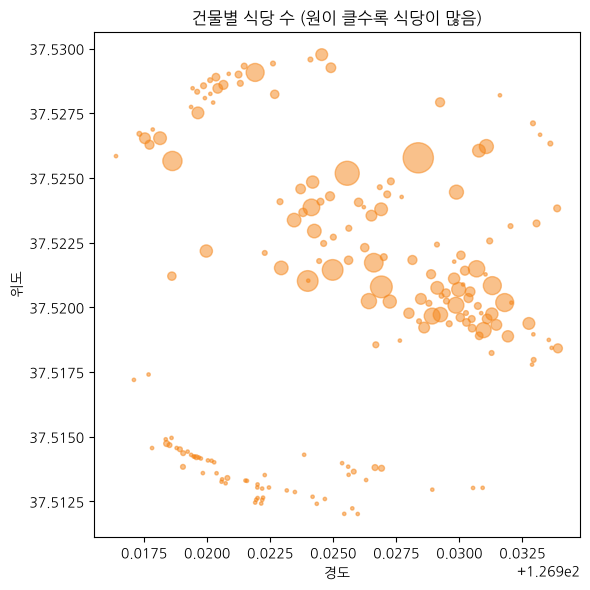

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
sizes = meal.groupby("address").agg(n=("restaurant_id", "size"), x=("x", "mean"), y=("y", "mean"))
ax.scatter(sizes["x"], sizes["y"], s=sizes["n"] * 6, alpha=0.5, color="#F58518")
ax.set_title("건물별 식당 수 (원이 클수록 식당이 많음)")
ax.set_xlabel("경도"); ax.set_ylabel("위도")
plt.tight_layout(); plt.show()

**발견:** 여의도 식당은 거리에 흩어져 있지 않고 **대형 빌딩 식당가에 몰려 있습니다.** (정확한 비율은 위 출력 참고)

추천 설계에 주는 의미:
- "건물" 단위로 묶어 보여주면 고르기 쉽습니다 (예: "○○빌딩 지하에 한식 12곳").
- 같은 건물 식당끼리는 **거리 조건이 같으므로**, 나중에 비교할 때 좋은 짝이 됩니다 (인과분석의 매칭).

## 4. 프랜차이즈(지점) 비율

In [11]:
meal["지점형"] = meal["name"].str.contains(r"점$", regex=True)
print(f"이름이 '~점'으로 끝나는 식당: {meal['지점형'].mean() * 100:.0f}%")
meal.groupby("menu_category")["지점형"].mean().loc[top].mul(100).round(0).rename("지점형 비율(%)").to_frame()

이름이 '~점'으로 끝나는 식당: 43%


,지점형 비율(%)
menu_category,
한식,40.0
고기,49.0
술집,23.0
일식,43.0
양식,44.0
횟집·해산물,31.0
중식,49.0
분식,55.0


## 5. 정리 (보고서로 가져갈 내용)

| 발견 | 근거 | 다음 단계에 주는 의미 |
|---|---|---|
| 한식·고기·술집·일식이 가장 많음 | 1번 표 | 메뉴 카테고리 3단계에서 이 넷을 먼저 세분화 |
| 식사용 아닌 곳이 섞여 있음 | 1번 아래 | 추천 후보에서 제외 규칙 필요 (`decisions`에 기록) |
| 식당이 소수 빌딩에 몰림 | 3번 | 건물 단위 보기, 같은 건물끼리 비교 |
| 거리 분포가 메뉴마다 다름 | 2번 | 거리는 인과분석의 혼란변수 |
| 가격·별점 정보 없음 | 0번 | 리뷰 데이터(예시·가상)에서 만들어야 함 |

**해석의 범위:** 카카오에 등록된 식당만 셌습니다. 등록 안 된 곳, 문 닫은 곳이 섞여 있을 수 있습니다.